# Adding risks: the simple sum, variance-covariance and a first diversification benefit

**Question:** Banco Andino carries four risks that each need capital: how much capital does it need in total, and how much of
that total depends on the way the four are added up?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebook 01 of topic 01 (open a committed artifact); no other topic is needed
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- read the four marginals of Banco Andino (credit, market, interest rate risk in the banking book and operational risk)
  and say what its expected loss, VaR, expected shortfall and economic capital are;
- add the four capitals in the two simplest ways, the simple sum (perfect dependence) and the square-root rule with an
  inter-risk correlation matrix, and see the engine refuse three invalid matrices;
- turn a total into a diversification factor and a benefit, watch the benefit shrink to nothing as the correlation rises,
  and read the benefit that each risk gets;
- explain why the simple sum is not an upper bound for a VaR, with the committed worst case as evidence.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. 
The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Imports, versions and the reader of the committed documents (three folders below the repository root)
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.aggregation import simple
from riskvalidation.validation import aggregation as agg_tests

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))
DERIVED = Path("../../..").resolve() / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

This notebook reads the capital-and-stress case of Contraste, **C18**: how much capital a bank needs once its risks are added up, and how much of the answer depends on the way they are added.

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 1.0.1 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** `data/derived/C18/baseline.json` (the baseline scenario: its `outputs.aggregation` block holds the four marginals, the correlation matrix, the band of aggregation methods, the Euler allocation and the diversification) and `data/derived/C18/t-copula-baseline.json` (the same aggregation with the Rosenberg and Schuermann reference). Every path is relative to the repository root.
- **What the document does not hold:** the million simulated losses behind each marginal. It holds four summary numbers per marginal, which is all this notebook needs; notebooks 02 and 03 of this topic rebuild simulation from them.

The next cell reads the baseline document, which a missing file would stop with its path.

In [2]:
# Read the baseline scenario: the aggregation block holds the marginals, the matrix and the band
baseline = read_json("C18/baseline.json")
agg = baseline["outputs"]["aggregation"]
marginals = agg["marginals"]
risks = [m["risk"] for m in marginals]
LABEL = {"credit": "credit", "market": "market", "irrbb": "interest rate",
         "operational": "operational"}
names = [LABEL[r] for r in risks]
band = {(row["method"], row["nu"]): row for row in agg["band"]}

## Method

### Step 1: the capital of each risk

Contraste measures every risk over **one year at the 99.9 percent level** and works with **economic capital**, the unexpected loss: the VaR of the loss distribution less its expected loss,

$$EC = \mathrm{VaR}_{0.999}(L) - \mathrm{EL}.$$

The expected shortfall (ES) is the mean loss beyond the VaR. The document holds the four numbers for each risk, in CLP millions.

The next cell draws, for each risk, the expected loss, the economic capital, the VaR and the expected shortfall that the
document holds, in CLP billions.

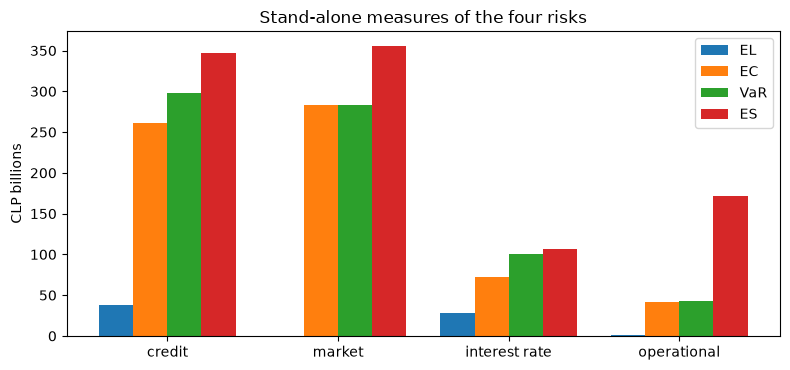

In [3]:
# The four stand-alone measures of every risk, in CLP billions
ec = np.array([m["ec_clp_m"] for m in marginals])
measures = {"EL": "el_clp_m", "EC": "ec_clp_m", "VaR": "var_clp_m", "ES": "es_clp_m"}
x = np.arange(len(risks))
fig, ax = plt.subplots(figsize=(8, 3.8))
for k, (label, key) in enumerate(measures.items()):
    ax.bar(x + (k - 1.5) * 0.2, [m[key] / 1e3 for m in marginals], width=0.2, label=label)
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("CLP billions")
ax.set_title("Stand-alone measures of the four risks")
ax.legend()
fig.tight_layout()
plt.show()

Credit and market risk are the two big ones, each close to CLP 260 to 285 billion of economic capital, interest rate risk
is a quarter of that and operational risk smaller still. Look at operational risk: its expected shortfall (CLP 171
billion) is four times its VaR, which is the signature of a heavy tail, while market risk has no expected loss at all
because its losses are centred on zero. The figure shows four stand-alone numbers per risk and nothing about how the
risks move together, which is what the rest of the notebook is about.

### Step 2: the simple sum

The simplest total adds the four capitals,

$$EC_{\text{tot}} = \sum_k EC_k.$$

It assumes the four bad years always come together (perfect dependence), and it is the **headline capital** of the case: the Chilean internal assessment adds up the capital needed for each risk. Every other figure of this notebook is information shown beside it, never a replacement.

The next cell adds the four capitals with the engine's `simple_sum` and prints the total beside the share of each risk.

In [4]:
# Sum the four economic capitals with the engine and print each risk's share of the sum
total_simple = simple.simple_sum(ec)
print("simple sum, CLP millions", round(total_simple, 1))
for risk, value in zip(risks, ec):
    print(f"{LABEL[risk]:16s} {value:10,.0f} {value / total_simple:6.1%}")

simple sum, CLP millions 658045.9
credit              260,607  39.6%
market              283,435  43.1%
interest rate        72,824  11.1%
operational          41,179   6.3%


### Step 3: the inter-risk correlation matrix

Bad years do not always coincide, so a bank may add the capitals with a correlation matrix $R$ instead. The matrix of this case is a convention taken from Rosenberg and Schuermann (2006): market with credit 0.5, market and credit with operational risk 0.2, and the document extends the 0.5 to interest rate risk. A matrix is only usable if it is symmetric, has a unit diagonal, entries in $[-1, 1]$ and no negative eigenvalue (positive semi-definite). `check_correlation` checks all four and raises `ValueError` otherwise.

The next cell validates the committed matrix with `check_correlation` and then offers it three invalid matrices, each of
which the engine must refuse.

In [5]:
# Validate the committed matrix, then show three invalid matrices being refused
R = np.array(agg["correlation"]["matrix"])
simple.check_correlation(R)
print("smallest eigenvalue of the committed matrix", round(float(np.linalg.eigvalsh(R)[0]), 4))
invalid = {
    "not positive semi-definite": [[1, 0.9, -0.9], [0.9, 1, 0.9], [-0.9, 0.9, 1]],
    "not symmetric": [[1, 0.5], [0.2, 1]],
    "diagonal is not 1": [[2, 0.5], [0.5, 1]],
}
for why, matrix in invalid.items():
    try:
        simple.check_correlation(np.array(matrix, dtype=float))
        print(why, ": accepted")
    except ValueError:
        print(why, ": refused")

smallest eigenvalue of the committed matrix 0.5
not positive semi-definite : refused
not symmetric : refused
diagonal is not 1 : refused


### Step 4: variance-covariance, the square-root rule

With a valid matrix the total capital is

$$EC_{\text{tot}} = \sqrt{EC^{\top} R \, EC} = \sqrt{\sum_{j}\sum_{k} R_{jk}\, EC_j\, EC_k}.$$

It is exact when the losses are elliptical with a common quantile scaling, and an approximation otherwise (dossier 05, G.1). Two limits tell you what the rule does: with $R = I$ (independent risks) it is the root of the sum of squares, and with $R$ all ones (perfect dependence) it is the simple sum.

The next cell calls `variance_covariance` and then the two limits: the identity matrix against the root of the sum of
squares, and the all-ones matrix against the simple sum.

In [6]:
# The square-root rule on the committed matrix and on its two limits
total_vc = simple.variance_covariance(ec, R)
independent = simple.variance_covariance(ec, np.eye(4))
comonotone = simple.variance_covariance(ec, np.ones((4, 4)))
print("square-root rule", round(total_vc, 1))
root_squares = float(np.sqrt((ec ** 2).sum()))
print("identity matrix", round(independent, 1), "root of the sum of squares", round(root_squares, 1))
print("all-ones matrix", round(comonotone, 1), "simple sum", round(total_simple, 1))

square-root rule 528106.3
identity matrix 394018.8 root of the sum of squares 394018.8
all-ones matrix 658045.9 simple sum 658045.9


### Step 5: the diversification factor and what drives it

The **diversification factor** is the total over the sum of the stand-alone capitals,

$$DF = \frac{\rho(L)}{\sum_k \rho(L_k)},$$

and the **benefit** is $1 - DF$. A factor below 1 means the risks do not all go wrong together. The factor is not forced to be at most 1: a VaR is not subadditive, and the engine never repairs a factor above 1 (step 7).

The next cell computes the factor of the square-root total with `diversification_factor`, sweeps one common correlation
from 0 to 1 and draws the benefit against it, with the case's own matrix marked.

factor and benefit of the case 0.8025 0.1975
benefit, percent 19.75


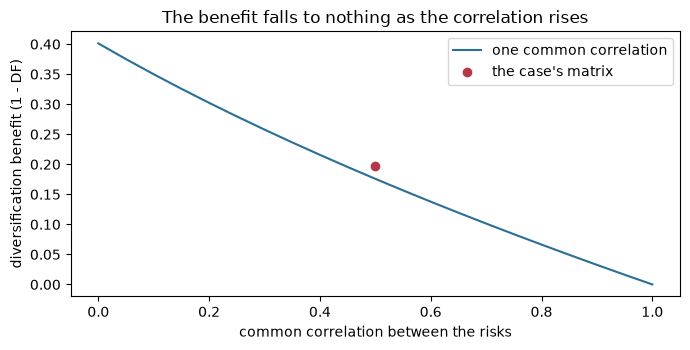

benefit at common correlation 0, 0.5 and 1 [0.4012, 0.1758, 0.0]


In [7]:
# The diversification factor of the square-root total and the benefit as one common correlation runs from 0 to 1
factor = simple.diversification_factor(total_vc, ec)
print("factor and benefit of the case", round(factor, 4), round(1 - factor, 4))
print("benefit, percent", round((1 - factor) * 100, 2))
rhos = np.linspace(0, 1, 21)
benefit = []
for rho in rhos:
    common = np.full((4, 4), rho) + (1 - rho) * np.eye(4)
    benefit.append(1 - simple.diversification_factor(simple.variance_covariance(ec, common), ec))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(rhos, benefit, color="#2a6f97", label="one common correlation")
ax.scatter([0.5], [1 - factor], color="#b23a48", zorder=3, label="the case's matrix")
ax.set_xlabel("common correlation between the risks")
ax.set_ylabel("diversification benefit (1 - DF)")
ax.set_title("The benefit falls to nothing as the correlation rises")
ax.legend()
fig.tight_layout()
plt.show()
print("benefit at common correlation 0, 0.5 and 1", [round(benefit[i], 4) for i in (0, 10, 20)])

The curve is the whole argument for validating a correlation matrix before using it. With independent risks the
square-root rule gives a benefit of about 40 percent, with a common correlation of 0.5 about 18 percent and with perfect
dependence none. The red dot is the case's own matrix, which is not a common correlation but a convention (0.5 between
market, credit and interest rate risk, 0.2 with operational risk), and it lands at 19.75 percent, a little above the 0.5
curve because operational risk is only weakly tied to the rest. The figure shows the rule's sensitivity to its input; it
does not say which correlation is right, and no number in the document does.

### Step 6: who gets the benefit

A total can be split among the risks by the **Euler principle** (Tasche, 2007): the contribution of risk $k$ is the derivative of the total with respect to the size of that risk, and the contributions add up to the total. The document allocates the expected shortfall of the Gaussian-copula aggregate this way (notebook 02 shows how). The **Euler benefit of a risk** is $1 - \rho(L_k \mid L) / \rho(L_k)$: its contribution against its stand-alone measure.

The next cell takes the committed Euler contributions of the expected shortfall, recomputes each risk's benefit with
`euler_diversification_benefit` and draws the stand-alone expected shortfall against the contribution of each risk.

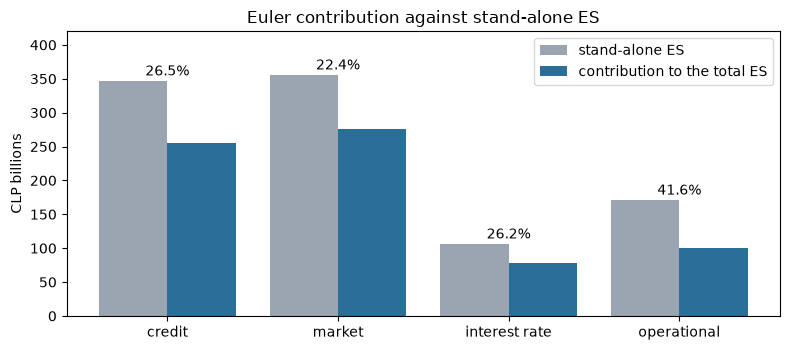

{'credit': 0.2653, 'market': 0.2243, 'interest rate': 0.2617, 'operational': 0.4159}


In [8]:
# Each risk's Euler benefit from its committed contribution and its stand-alone expected shortfall
contribution = {row["risk"]: row["contribution_clp_m"] for row in agg["euler"]["allocation"]}
euler_benefit = [simple.euler_diversification_benefit(contribution[m["risk"]], m["es_clp_m"]) for m in marginals]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(x - 0.2, [m["es_clp_m"] / 1e3 for m in marginals], width=0.4, label="stand-alone ES", color="#9aa5b1")
parts = [contribution[r] / 1e3 for r in risks]
ax.bar(x + 0.2, parts, width=0.4, label="contribution to the total ES", color="#2a6f97")
for k, value in enumerate(euler_benefit):
    ax.text(k, 8 + marginals[k]["es_clp_m"] / 1e3, f"{value:.1%}", ha="center")
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(0, 420)
ax.set_ylabel("CLP billions")
ax.set_title("Euler contribution against stand-alone ES")
ax.legend()
fig.tight_layout()
plt.show()
print(dict(zip(names, [round(b, 4) for b in euler_benefit])))

Every grey bar is higher than its blue neighbour, because each risk contributes less to the tail of the total than it
would alone: that gap is its Euler benefit, written above the bars. Operational risk gets the largest benefit (41.6
percent) since its loss is large only in years when the others are not, and market risk the smallest (22.4 percent)
because it is tied hardest to credit and interest rate risk. These benefits are measured on the expected shortfall of the
Gaussian-copula aggregate, so they cannot be compared with the 19.75 percent of the square-root total: a different
total, a different risk measure, a different number.

### Step 7: the simple sum is not an upper bound

It is natural to read the simple sum as the most capital the four risks can ever need. For a VaR it is not: **a VaR is not subadditive**, so the VaR of a sum can exceed the sum of the VaRs (Embrechts, McNeil and Straumann, 2002; Embrechts, Puccetti and Rueschendorf, 2013). The band of the document includes the **worst case** over every possible dependence between these four marginals, computed by the rearrangement algorithm (notebook 03).

The next cell turns the committed worst case into a factor and runs the engine's `diversification_sign` test twice, over
the diversified rows alone and with the worst case added.

In [9]:
# Turn the committed worst case into a factor and run the sign test with and without it
worst = band[("worst-case", None)]["capital_clp_m"]
worst_factor = simple.diversification_factor(worst, ec)
diversified = [r["diversification_factor"] for r in agg["band"]
               if r["method"] in ("variance-covariance", "gaussian-copula", "t-copula")]
cases = (("diversified rows only", diversified),
         ("with the worst case", diversified + [worst_factor]))
for label, factors in cases:
    result = agg_tests.diversification_sign(factors)
    print(f"{label:30s} largest factor {result.statistic:.4f}  rows above 1 {result.extras['count_above_one']}")
print("worst case, CLP millions", round(worst, 1), "over the simple sum", round(worst_factor, 4))

diversified rows only          largest factor 0.8394  rows above 1 0
with the worst case            largest factor 1.2512  rows above 1 1
worst case, CLP millions 823331.5 over the simple sum 1.2512


### Step 8: a published reference, shown beside the result and never as a gate

Rosenberg and Schuermann (2006) found that the additive approximation, which assumes no diversification, typically overestimates risk by about 30 to 40 percent for a typical large bank. The engine's `rosenberg_schuermann_reference` computes the same ratio for this case, simple sum over Gaussian-copula capital less 1, and states whether it falls in that range. The test is always green: the row exists to be shown.

The next cell calls `rosenberg_schuermann_reference` with the simple sum and the Gaussian-copula capital of the band.

In [10]:
# The additive overestimate of this case, simple sum over Gaussian-copula capital less one
gaussian = band[("gaussian-copula", None)]["capital_clp_m"]
reference = agg_tests.rosenberg_schuermann_reference(total_simple, gaussian)
print("additive overestimate", round(reference.statistic, 4))
print("published range", "30 to 40 percent")

additive overestimate 0.3376
published range 30 to 40 percent


## Results

The last figure lays the whole ladder side by side: every row of the committed band, with the simple sum as a vertical
line. The two bars in blue are the ones this notebook recomputed in closed form.

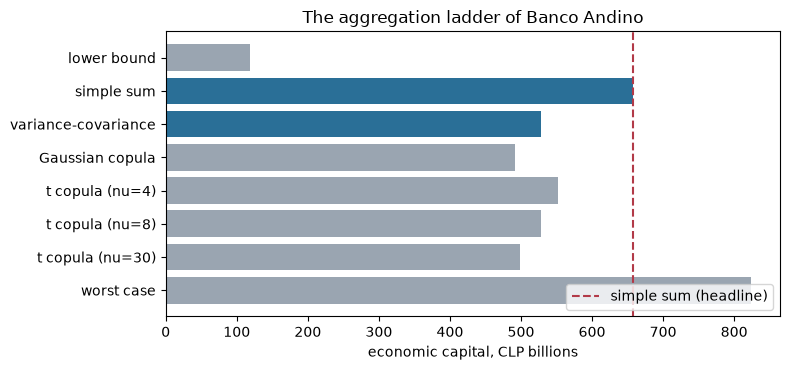

In [11]:
# Draw the committed band as bars with the simple sum as a vertical line, and mark the rows recomputed here
names = {"lower-bound": "lower bound", "simple-sum": "simple sum",
         "variance-covariance": "variance-covariance", "gaussian-copula": "Gaussian copula",
         "t-copula": "t copula", "worst-case": "worst case"}
labels = [names[r["method"]] + (f" (nu={r['nu']:g})" if r["nu"] else "") for r in agg["band"]]
recomputed = {names["simple-sum"], names["variance-covariance"]}
colours = ["#2a6f97" if label in recomputed else "#9aa5b1" for label in labels]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(labels[::-1], [r["capital_clp_m"] / 1e3 for r in agg["band"]][::-1], color=colours[::-1])
ax.axvline(total_simple / 1e3, color="#b23a48", linestyle="--", label="simple sum (headline)")
ax.set_xlabel("economic capital, CLP billions")
ax.set_title("The aggregation ladder of Banco Andino")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

Read the bars against the dashed line. Everything built on a correlation or a copula sits to its left, between CLP 492
and 552 billion, and the lower bound is far to the left because it is the best case in which the risks offset each
other. The worst case sits to the right of the line, which is the surprise of the step 7: for a VaR the sum of the
capitals is not the ceiling. The bars say where each method lands, not which is right, and the dependence band of
notebook 03 is built on exactly that spread.

**Answer:** the four capitals add to CLP 658,046 million (the simple sum, the headline of the case); the square-root rule
with the case's correlation matrix gives CLP 528,106 million, a factor of 0.8025 and a benefit of 19.75 percent, and the
benefit runs from 40 percent at correlation 0 to nothing at 1. The worst case, CLP 823,332 million, is 1.2512 times the
simple sum, so the sum is not an upper bound for a VaR: the sign test is green over the diversified rows (largest factor
0.8394) and red once the worst case is included. The additive overestimate of this case is 0.3376, inside the published
30 to 40 percent.

What this notebook does not show: the copula rows of the band were read, not recomputed, because the document holds summary
numbers and not the simulated losses (notebook 02 builds a simulation); and Banco Andino is synthetic, so none of these
figures is a statement about a real bank.

## Summary

- Economic capital is the VaR less the expected loss, per risk, over one year at 99.9 percent; the document holds the four numbers of each of the four risks.
- The simple sum is the headline capital; the square-root rule needs a valid correlation matrix, which `check_correlation` enforces.
- The diversification factor is the total over the sum of the capitals; its benefit shrinks to nothing as the correlation rises to 1.
- The Euler contributions add up to the total and give each risk its own benefit.
- A VaR is not subadditive: the committed worst case is above the simple sum, so the sum is not an upper bound, and the sign test turns red when it is included.
- The Rosenberg and Schuermann range is a reference to read beside the result, never a threshold.

**What to try next.** Change one off-diagonal entry of the matrix in step 3 and watch the factor of step 5 move. Then continue with notebook 02, which replaces the square-root rule by copulas and shows where the committed Gaussian and t rows come from.

## References

- Rosenberg, J. V. and Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Embrechts, P., Puccetti, G. and Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- Tasche, D. (2007), Capital allocation to business units and sub-portfolios: the Euler principle (arXiv 0708.2542). https://arxiv.org/abs/0708.2542
- Embrechts, P., McNeil, A. and Straumann, D. (2002), Correlation and dependence in risk management: properties and pitfalls, in Dempster (ed.), Risk Management: Value at Risk and Beyond, Cambridge University Press. https://doi.org/10.1017/CBO9780511615337.008
- This repository: `docs/contracts/engine/aggregation-api.md` (the engine's aggregation functions) and `docs/design/features/c18/requirements.md` (the requirements of the case).